In [1]:
# Etape 0: importation des bibliothèques
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.optimizers.schedules import CosineDecay
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
np.random.seed(42) # fixe le hasard pour NumPy (shuffle, split, etc.)
tf.random.set_seed(42) # fixe le hasard pour TensorFlow (initialisation des poids, etc.)

In [2]:
# Etape 1: Chargement du dataset
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

print("X_train_full :", X_train_full.shape)
print("y_train_full :", y_train_full.shape)
print("X_test       :", X_test.shape)
print("y_test       :", y_test.shape)
print("Classes      :", np.unique(y_train_full))

X_train_full : (60000, 28, 28)
y_train_full : (60000,)
X_test       : (10000, 28, 28)
y_test       : (10000,)
Classes      : [0 1 2 3 4 5 6 7 8 9]


In [3]:
# Etape 2: Prétraitement des images
# Conversion en float
X_train_full = X_train_full.astype("float32")
X_test = X_test.astype("float32")
# Normalisation simple [0,255] -> [0,1]
X_train_full = X_train_full / 255.0
X_test = X_test / 255.0
# Flatten : 28x28 -> 784
X_train_full = X_train_full.reshape(X_train_full.shape[0], 28 * 28)
X_test = X_test.reshape(X_test.shape[0], 28 * 28)
print("Après flatten :")
print("X_train_full :", X_train_full.shape)
print("X_test       :", X_test.shape)

Après flatten :
X_train_full : (60000, 784)
X_test       : (10000, 784)


In [4]:
#Etape 3: Split train / validation pour les baselines
X_train_base, X_val_base, y_train_base, y_val_base = train_test_split(
    X_train_full, y_train_full,
    test_size=0.2,
    stratify=y_train_full,
    random_state=42
)

print("X_train_base :", X_train_base.shape)
print("X_val_base   :", X_val_base.shape)

X_train_base : (48000, 784)
X_val_base   : (12000, 784)


In [5]:
#Etape 4: Standardisation
scaler_base = StandardScaler()

X_train_base_scaled = scaler_base.fit_transform(X_train_base)
X_val_base_scaled = scaler_base.transform(X_val_base)
X_test_base_scaled = scaler_base.transform(X_test)

In [6]:
# Etape 5: Préparation de fonctions nécessaires
# Fonction de création de modèle
def build_model(input_dim, hidden_layers=(128,),
                activation="relu", optimizer_name="adam",
                learning_rate=0.001, use_cosine=False,
                steps_per_epoch=None, epochs=None):
    model = Sequential()
    model.add(Input(shape=(input_dim,)))
    for units in hidden_layers:
        model.add(Dense(units, activation=activation))
    model.add(Dense(10, activation="softmax"))
    # Learning rate fixe ou Cosine Decay
    if use_cosine:
        lr = CosineDecay(
            initial_learning_rate=learning_rate,
            decay_steps=steps_per_epoch * epochs,
            alpha=0.1 )
    else:
        lr = learning_rate
    # Optimiseur
    if optimizer_name == "adam":
        optimizer = Adam(learning_rate=lr)
    else:
        optimizer = SGD(learning_rate=lr)
    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"] )
    return model

In [7]:
# Etape 5: Préparation de fonctions nécessaires
# Fonction d'évaluation
def evaluate_model(y_true, y_pred, model_name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro")
    rec = recall_score(y_true, y_pred, average="macro")
    print(f"\n=== {model_name} ===")
    print(f"Accuracy        : {acc:.4f}")
    print(f"Precision_macro : {prec:.4f}")
    print(f"Recall_macro    : {rec:.4f}")
    print("\nClassification report :")
    print(classification_report(y_true, y_pred))
    return acc, prec, rec

In [8]:
# Fonction de régularisation EarlyStopping
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=7,
    min_delta=0.001,
    restore_best_weights=True
)

In [9]:
# Etape 6: Partie A — construction et évaluation d'un Baseline learning rate fixe
baseline_fixed = build_model(
    input_dim=X_train_base_scaled.shape[1],
    hidden_layers=(128,),
    activation="relu",
    optimizer_name="adam",
    learning_rate=0.001,
    use_cosine=False
)
history_fixed = baseline_fixed.fit(
    X_train_base_scaled, y_train_base,
    validation_data=(X_val_base_scaled, y_val_base),
    epochs=25,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.8300 - loss: 0.4825 - val_accuracy: 0.8671 - val_loss: 0.3763
Epoch 2/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8748 - loss: 0.3445 - val_accuracy: 0.8768 - val_loss: 0.3507
Epoch 3/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8904 - loss: 0.2994 - val_accuracy: 0.8827 - val_loss: 0.3414
Epoch 4/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9008 - loss: 0.2702 - val_accuracy: 0.8850 - val_loss: 0.3401
Epoch 5/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9095 - loss: 0.2466 - val_accuracy: 0.8851 - val_loss: 0.3402
Epoch 6/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9178 - loss: 0.2262 - val_accuracy: 0.8857 - val_loss: 0.3418
Epoch 7/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9245 - loss: 0.2096 - val_accuracy: 0.8845 - val_loss: 0.3455
Epoch 8/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9305 - loss: 0.1943 - val_accuracy: 0

In [10]:
y_pred_fixed = np.argmax(baseline_fixed.predict(X_test_base_scaled, verbose=0), axis=1)
fixed_acc, fixed_prec, fixed_rec = evaluate_model(
    y_test, y_pred_fixed, "Baseline LR fixe"
)


=== Baseline LR fixe ===
Accuracy        : 0.8687
Precision_macro : 0.8696
Recall_macro    : 0.8687

Classification report :
              precision    recall  f1-score   support

           0       0.84      0.82      0.83      1000
           1       0.98      0.97      0.97      1000
           2       0.77      0.75      0.76      1000
           3       0.85      0.90      0.88      1000
           4       0.74      0.83      0.78      1000
           5       0.97      0.92      0.94      1000
           6       0.72      0.63      0.67      1000
           7       0.89      0.98      0.93      1000
           8       0.98      0.95      0.97      1000
           9       0.97      0.93      0.95      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



In [11]:
# Etape 7: Partie B — construction et évaluation d'un modèle à base de Cosine Delay
steps_per_epoch = int(np.ceil(X_train_base_scaled.shape[0] / 128))

baseline_cosine = build_model(
    input_dim=X_train_base_scaled.shape[1],
    hidden_layers=(128,),
    activation="relu",
    optimizer_name="adam",
    learning_rate=0.001,
    use_cosine=True,
    steps_per_epoch=steps_per_epoch,
    epochs=25
)

history_cosine = baseline_cosine.fit(
    X_train_base_scaled, y_train_base,
    validation_data=(X_val_base_scaled, y_val_base),
    epochs=25,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8305 - loss: 0.4836 - val_accuracy: 0.8691 - val_loss: 0.3821
Epoch 2/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8746 - loss: 0.3457 - val_accuracy: 0.8788 - val_loss: 0.3531
Epoch 3/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8906 - loss: 0.3004 - val_accuracy: 0.8821 - val_loss: 0.3456
Epoch 4/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9019 - loss: 0.2695 - val_accuracy: 0.8832 - val_loss: 0.3392
Epoch 5/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9116 - loss: 0.2437 - val_accuracy: 0.8859 - val_loss: 0.3343
Epoch 6/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9193 - loss: 0.2226 - val_accuracy: 0.8861 - val_loss: 0.3366
Epoch 7/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9254 - loss: 0.2053 - val_accuracy: 0.8881 - val_loss: 0.3378
Epoch 8/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9316 - loss: 0.1894 - val_accuracy: 0

In [12]:
y_pred_cosine = np.argmax(baseline_cosine.predict(X_test_base_scaled, verbose=0), axis=1)

cos_acc, cos_prec, cos_rec = evaluate_model(
    y_test, y_pred_cosine, "Baseline Cosine Decay"
)


=== Baseline Cosine Decay ===
Accuracy        : 0.8740
Precision_macro : 0.8745
Recall_macro    : 0.8740

Classification report :
              precision    recall  f1-score   support

           0       0.85      0.84      0.84      1000
           1       0.98      0.97      0.98      1000
           2       0.76      0.78      0.77      1000
           3       0.88      0.89      0.88      1000
           4       0.74      0.84      0.79      1000
           5       0.97      0.94      0.95      1000
           6       0.72      0.61      0.66      1000
           7       0.90      0.97      0.93      1000
           8       0.98      0.96      0.97      1000
           9       0.97      0.94      0.95      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



In [13]:
# Etape 8: Comparaison des deux baselines
comparison_baselines = pd.DataFrame({
    "Modèle": ["Baseline LR fixe", "Baseline Cosine Decay"],
    "Accuracy": [fixed_acc, cos_acc],
    "Precision_macro": [fixed_prec, cos_prec],
    "Recall_macro": [fixed_rec, cos_rec]
})

print(comparison_baselines)

                  Modèle  Accuracy  Precision_macro  Recall_macro
0       Baseline LR fixe    0.8687         0.869556        0.8687
1  Baseline Cosine Decay    0.8740         0.874492        0.8740


**Q4 - Intérprétation des résultats obtenus**:Les résultats montrent que le modèle utilisant la stratégie Cosine Decay obtient de meilleures performances que celui avec un learning rate fixe, avec une amélioration d’environ 0.5% sur l’ensemble des métriques (accuracy, précision et recall). Cette amélioration, bien que modérée, est cohérente et s’explique par la capacité du Cosine Decay à adapter dynamiquement le taux d’apprentissage au cours de l’entraînement : un learning rate plus élevé en début d’apprentissage favorise une exploration efficace de l’espace des solutions, tandis qu’une diminution progressive en fin d’entraînement permet un ajustement plus fin des poids et une convergence plus stable. À l’inverse, un learning rate fixe ne s’adapte pas aux différentes phases de l’apprentissage, ce qui peut limiter la qualité de convergence.


In [14]:
# Etape 9: Partie C: Recherche manuelle d’hyperparamètres avec CV stratifiée
# Grille manuelle
param_grid = [

    {"hidden_layers": (64,), "activation": "relu", "optimizer_name": "adam",
     "batch_size": 128, "epochs": 30, "learning_rate": 0.001},

    {"hidden_layers": (128,), "activation": "relu", "optimizer_name": "adam",
     "batch_size": 64, "epochs": 25, "learning_rate": 0.001},

    {"hidden_layers": (256,), "activation": "relu", "optimizer_name": "adam",
     "batch_size": 128, "epochs": 23, "learning_rate": 0.01},

    {"hidden_layers": (128, 64), "activation": "relu", "optimizer_name": "adam",
     "batch_size": 32, "epochs": 20, "learning_rate": 0.005},

    {"hidden_layers": (128,), "activation": "tanh", "optimizer_name": "adam",
     "batch_size": 64, "epochs": 25, "learning_rate": 0.001},

    {"hidden_layers": (128,), "activation": "relu", "optimizer_name": "sgd",
     "batch_size": 64, "epochs": 25, "learning_rate": 0.01},
]

In [15]:
# Etape 10: Validation croisée stratifiée
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
results = []
for params in param_grid:
    fold_accuracies = []
    fold_precisions = []
    fold_recalls = []
    for train_idx, val_idx in cv.split(X_train_full, y_train_full):
        X_tr = X_train_full[train_idx]
        X_val = X_train_full[val_idx]
        y_tr = y_train_full[train_idx]
        y_val = y_train_full[val_idx]
        # scaler séparé dans chaque fold
        scaler_cv = StandardScaler()
        X_tr_scaled = scaler_cv.fit_transform(X_tr)
        X_val_scaled = scaler_cv.transform(X_val)
        steps_per_epoch_cv = int(np.ceil(X_tr_scaled.shape[0] / params["batch_size"]))
        model = build_model(
            input_dim=X_tr_scaled.shape[1],
            hidden_layers=params["hidden_layers"],
            activation=params["activation"],
            optimizer_name=params["optimizer_name"],
            learning_rate=params["learning_rate"],
            use_cosine=True,
            steps_per_epoch=steps_per_epoch_cv,
            epochs=params["epochs"] )
        early_stop_cv = EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True )
        model.fit(
            X_tr_scaled, y_tr,
            validation_data=(X_val_scaled, y_val),
            epochs=params["epochs"],
            batch_size=params["batch_size"],
            callbacks=[early_stop_cv],
            verbose=0 )

        y_val_pred = np.argmax(model.predict(X_val_scaled, verbose=0), axis=1)
        acc = accuracy_score(y_val, y_val_pred)
        prec = precision_score(y_val, y_val_pred, average="macro")
        rec = recall_score(y_val, y_val_pred, average="macro")

        fold_accuracies.append(acc)
        fold_precisions.append(prec)
        fold_recalls.append(rec)

    results.append({
        "hidden_layers": params["hidden_layers"],
        "activation": params["activation"],
        "optimizer_name": params["optimizer_name"],
        "batch_size": params["batch_size"],
        "epochs": params["epochs"],
        "learning_rate": params["learning_rate"],
        "mean_cv_accuracy": np.mean(fold_accuracies),
        "mean_cv_precision": np.mean(fold_precisions),
        "mean_cv_recall": np.mean(fold_recalls),
        "std_cv_accuracy": np.std(fold_accuracies)
    })

In [16]:
# Etape 11: Construction du tableau de résultat
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="mean_cv_accuracy", ascending=False).reset_index(drop=True)

print(results_df)

  hidden_layers activation optimizer_name  batch_size  epochs  learning_rate  \
0        (128,)       relu           adam          64      25          0.001   
1         (64,)       relu           adam         128      30          0.001   
2        (128,)       relu            sgd          64      25          0.010   
3        (128,)       tanh           adam          64      25          0.001   
4     (128, 64)       relu           adam          32      20          0.005   
5        (256,)       relu           adam         128      23          0.010   

   mean_cv_accuracy  mean_cv_precision  mean_cv_recall  std_cv_accuracy  
0          0.879983           0.880123        0.879983         0.001721  
1          0.879783           0.879658        0.879783         0.002998  
2          0.877583           0.877077        0.877583         0.001195  
3          0.877183           0.876336        0.877183         0.001391  
4          0.859767           0.864354        0.859767         0.0080

In [17]:
# Tableau des résultats
best_config = results_df.iloc[0]
print(best_config)

hidden_layers          (128,)
activation               relu
optimizer_name           adam
batch_size                 64
epochs                     25
learning_rate           0.001
mean_cv_accuracy     0.879983
mean_cv_precision    0.880123
mean_cv_recall       0.879983
std_cv_accuracy      0.001721
Name: 0, dtype: object


In [18]:
# Etape 12: Bloc D: entrainement final du meilleur modèle
# Standardisation finale
scaler_final = StandardScaler()
X_train_full_scaled = scaler_final.fit_transform(X_train_full)
X_test_scaled = scaler_final.transform(X_test)


In [19]:
# Construction du meilleur modèle
best_hidden_layers = best_config["hidden_layers"]
best_activation = best_config["activation"]
best_optimizer_name = best_config["optimizer_name"]
best_batch_size = int(best_config["batch_size"])
best_epochs = int(best_config["epochs"])
best_learning_rate = float(best_config["learning_rate"])

steps_per_epoch_final = int(np.ceil(X_train_full_scaled.shape[0] / best_batch_size))
best_model = build_model(
    input_dim=X_train_full_scaled.shape[1],
    hidden_layers=best_hidden_layers,
    activation=best_activation,
    optimizer_name=best_optimizer_name,
    learning_rate=best_learning_rate,
    use_cosine=True,
    steps_per_epoch=steps_per_epoch_final,
    epochs=best_epochs
)

In [20]:
# Entrainement final
early_stop_final = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)
history_best = best_model.fit(
    X_train_full_scaled, y_train_full,
    validation_split=0.1,
    epochs=best_epochs,
    batch_size=best_batch_size,
    callbacks=[early_stop_final],
    verbose=1
)

Epoch 1/25
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8388 - loss: 0.4583 - val_accuracy: 0.8638 - val_loss: 0.3658
Epoch 2/25
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8791 - loss: 0.3344 - val_accuracy: 0.8730 - val_loss: 0.3509
Epoch 3/25
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8932 - loss: 0.2922 - val_accuracy: 0.8822 - val_loss: 0.3359
Epoch 4/25
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9045 - loss: 0.2607 - val_accuracy: 0.8837 - val_loss: 0.3321
Epoch 5/25
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9138 - loss: 0.2375 - val_accuracy: 0.8842 - val_loss: 0.3349
Epoch 6/25
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9213 - loss: 0.2171 - val_accuracy: 0.8858 - val_loss: 0.3383
Epoch 7/25
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9292 - loss: 0.1976 - val_accuracy: 0.8858 - val_loss: 0.3481


In [21]:
# Évaluation finale sur le vrai test
y_pred_best = np.argmax(best_model.predict(X_test_scaled, verbose=0), axis=1)

best_acc, best_prec, best_rec = evaluate_model(
    y_test, y_pred_best, "Meilleur modèle final"
)


=== Meilleur modèle final ===
Accuracy        : 0.8746
Precision_macro : 0.8755
Recall_macro    : 0.8746

Classification report :
              precision    recall  f1-score   support

           0       0.79      0.85      0.82      1000
           1       0.98      0.97      0.98      1000
           2       0.83      0.75      0.79      1000
           3       0.84      0.91      0.87      1000
           4       0.76      0.85      0.80      1000
           5       0.96      0.94      0.95      1000
           6       0.74      0.64      0.69      1000
           7       0.90      0.97      0.93      1000
           8       0.97      0.96      0.96      1000
           9       0.97      0.92      0.94      1000

    accuracy                           0.87     10000
   macro avg       0.88      0.87      0.87     10000
weighted avg       0.88      0.87      0.87     10000



**Q5 pourquoi une nouvelle standardisation des données est réalisée avant l’entraînement final du modèle ?**
Une fois la meilleure configuration identifiée, un entraînement final est réalisé sur l’ensemble de X_train_full. Dans ce contexte, une nouvelle standardisation est nécessaire, car lors de la CV, les scalers étaient ajustés séparément dans chaque fold ; ils ne sont donc pas réutilisables. Il faut ainsi entraîner un nouveau StandardScaler sur tout X_train_full afin d’assurer une transformation cohérente des données d’entraînement et du jeu de test, sans fuite d’information. Durant cet entraînement final, validation_split=0.1 crée automatiquement un sous-ensemble de validation (10%) utilisé uniquement par EarlyStopping pour contrôler le surapprentissage, et non pour la CV.

**Q5) Analyse des performances finales sur le jeu de test**: Les performances finales obtenues sur le jeu de test sont : Accuracy = 0.8746, Precision_macro = 0.8755 et Recall_macro = 0.8746, avec une F1-score macro d’environ 0.87. L’analyse du classification report montre que certaines classes sont très bien reconnues (par exemple classes 1, 7, 8, 9 avec des scores élevés), tandis que d’autres présentent plus de difficultés (notamment la classe 6 avec un recall plus faible), ce qui indique une variabilité de performance selon les classes.

**Q5) Conclusion sur la qualité du modèle obtenu**: Globalement, le modèle obtenu présente une bonne qualité de généralisation, avec des performances sur le test proches de celles observées en validation croisée (≈ 0.88), ce qui indique une bonne stabilité et l’absence de surapprentissage significatif. Malgré quelques faiblesses sur certaines classes, les résultats restent cohérents et satisfaisants pour un modèle MLP simple, confirmant la pertinence du choix des hyperparamètres et de la stratégie d’optimisation utilisée.

In [22]:
# Etape 13: Comparaison finale
# Tableau comparatif final
comparison_finale = pd.DataFrame({
    "Modèle": ["Baseline LR fixe", "Baseline Cosine Decay", "Best model manuel + CV"],
    "Accuracy": [fixed_acc, cos_acc, best_acc],
    "Precision_macro": [fixed_prec, cos_prec, best_prec],
    "Recall_macro": [fixed_rec, cos_rec, best_rec]
})

print(comparison_finale)

                   Modèle  Accuracy  Precision_macro  Recall_macro
0        Baseline LR fixe    0.8687         0.869556        0.8687
1   Baseline Cosine Decay    0.8740         0.874492        0.8740
2  Best model manuel + CV    0.8746         0.875486        0.8746


**Q6 a** : Les résultats montrent que le modèle Baseline LR fixe obtient une accuracy de 0.8687, tandis que l’introduction du Cosine Decay permet une légère amélioration à 0.8740, confirmant l’intérêt d’un learning rate adaptatif pour améliorer la convergence. Le modèle final optimisé (Best model avec CV) atteint une performance très proche (0.8746), ce qui en fait le modèle le plus performant, bien que l’écart avec Cosine Decay reste faible. Cela montre que le scheduling du learning rate apporte déjà un gain significatif, et que la recherche d’hyperparamètres permet un ajustement plus fin.

**Q6 b** : L’amélioration apportée par la recherche d’hyperparamètres reste modérée (gain très faible par rapport au modèle Cosine Decay). Cependant, elle est importante d’un point de vue méthodologique : la validation croisée permet de sélectionner une configuration plus robuste et stable, en réduisant la dépendance à un seul découpage des données. Ainsi, même si le gain en performance est limité sur cet exemple, la CV garantit un meilleur choix de modèle et une meilleure généralisation.

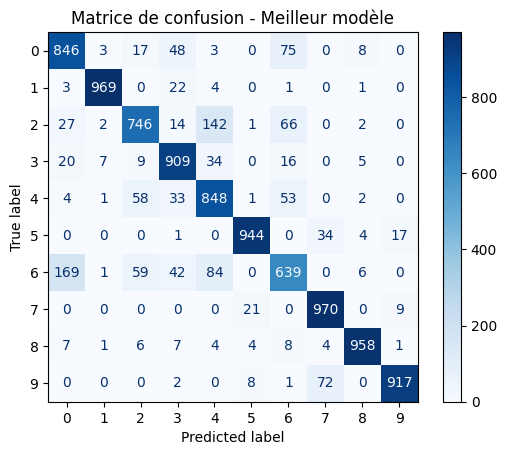

In [23]:
# Matrice de confusion
cm = confusion_matrix(y_test, y_pred_best)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion - Meilleur modèle")
plt.show()

In [24]:
np.bincount(y_test)

array([1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000])

**Q6 c** : La matrice de confusion présente une diagonale dominante, ce qui indique que les prédictions sont globalement correctes. La majorité des observations est correctement classée dans leur classe respective. Cependant, certaines classes présentent des confusions notables, indiquant que toutes les classes ne sont pas équivalentes en termes de difficulté de classification.

**Q6 d** : Dans Fashion-MNIST le test set contient 10 000 images.

**Classes les mieux reconnues** :
Les classes 1 (969/1000), 7 (970/1000), 8 (958/1000) et 9 (917/1000) présentent des taux de reconnaissance très élevés, avec peu d’erreurs.

**Classes les plus difficiles / confondues** :
La classe 6 est la plus difficile à prédire (639/1000 seulement correctement classés), avec de nombreuses confusions vers la classe 0 (169 cas) et la classe 4 (84 cas).
La classe 2 est également difficile (746/1000) avec une confusion importante vers la classe 4 (142 cas) et la classe 6 (66 cas).

**Q6 e**: Un exemple marquant est la confusion entre les classes 2 et 4 : la classe 2 est prédite comme 4 dans 142 cas, ce qui constitue une erreur importante. Cette confusion peut s’expliquer par une similarité visuelle entre les deux classes (dans Fashion-MNIST, certaines catégories de vêtements peuvent avoir des formes proches, comme des pulls et des manteaux). De même, la confusion entre la classe 6 et la classe 0 (169 cas) peut être due à des caractéristiques visuelles communes (formes ou textures similaires), rendant la séparation difficile pour un modèle MLP.

Le modèle obtenu est globalement performant, avec une bonne précision et une généralisation satisfaisante. Toutefois, l’analyse fine de la matrice de confusion montre que certaines classes restent difficiles à distinguer, ce qui suggère que des modèles plus avancés pourraient être nécessaires pour capturer des caractéristiques visuelles plus complexes.